In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the cleaned Netflix dataset
file_path = "/home/richard/Netflix_Fresh/data/cleaned/netflix_cleaned.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nRelease year range:")
print(df["release_year"].min(), "to", df["release_year"].max())
print("\nMissing release years:", df["release_year"].isna().sum())


Dataset loaded successfully!
Dataset shape: (8787, 10)

Release year range:
1925 to 2021

Missing release years: 0


In [2]:

# Count titles released in each year
yearly_counts = df["release_year"].value_counts().sort_index()

print("Titles by release year:")
print(yearly_counts)

print("\nTop 10 release years by number of titles:")
print(yearly_counts.sort_values(ascending=False).head(10))


Titles by release year:
release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1144
2019    1029
2020     953
2021     592
Name: count, Length: 74, dtype: int64

Top 10 release years by number of titles:
release_year
2018    1144
2017    1030
2019    1029
2020     953
2016     901
2021     592
2015     555
2014     352
2013     286
2012     236
Name: count, dtype: int64


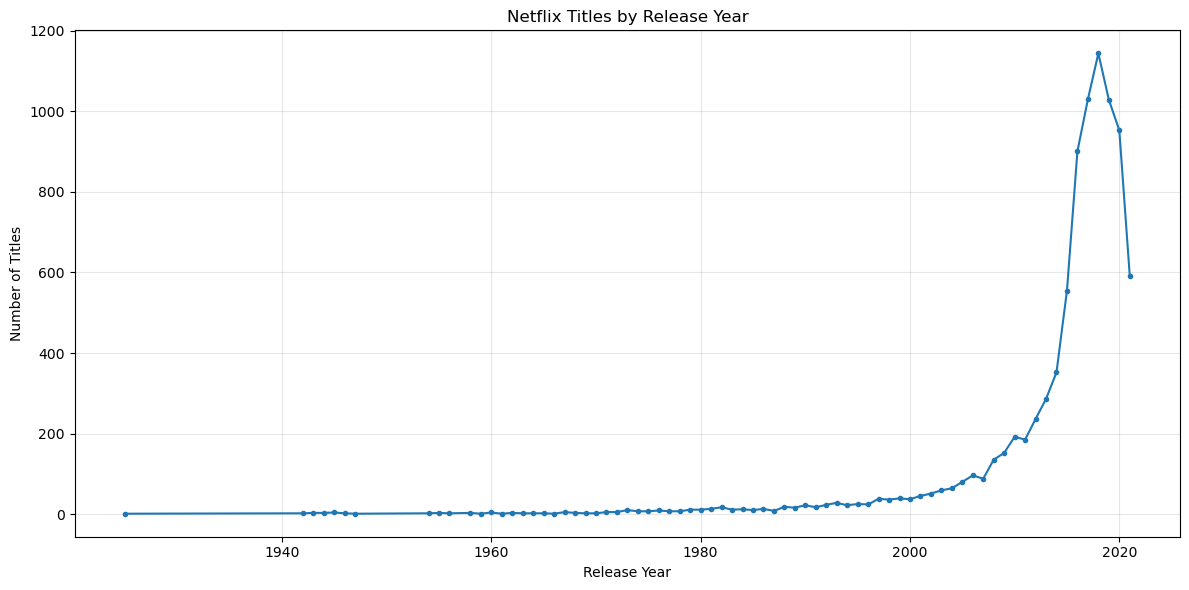

In [3]:

# Plot the number of titles by release year
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker="o",
    markersize=3,
    linewidth=1.5
)

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


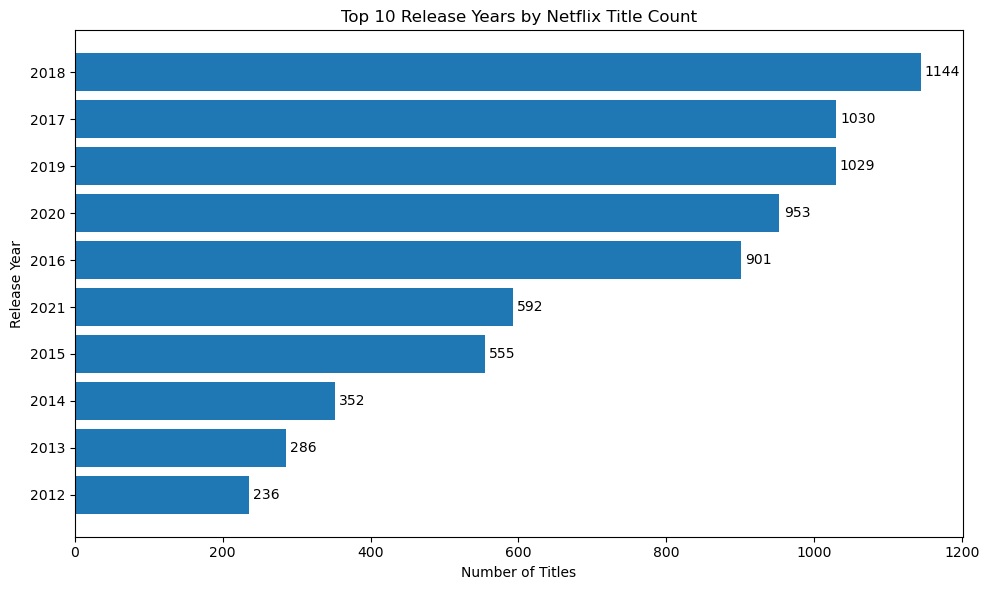

In [4]:

# Select the top 10 release years
top_10_years = yearly_counts.sort_values(ascending=False).head(10)
top_10_years = top_10_years.sort_values()

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_10_years.index.astype(str),
    top_10_years.values
)

plt.title("Top 10 Release Years by Netflix Title Count")
plt.xlabel("Number of Titles")
plt.ylabel("Release Year")
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()
plt.show()


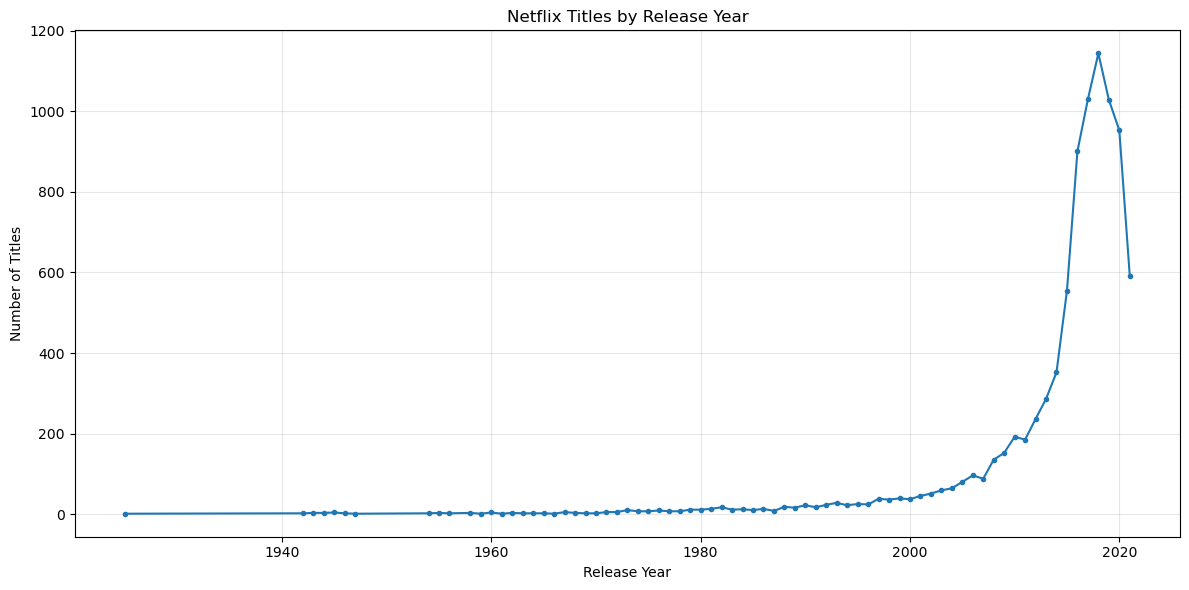

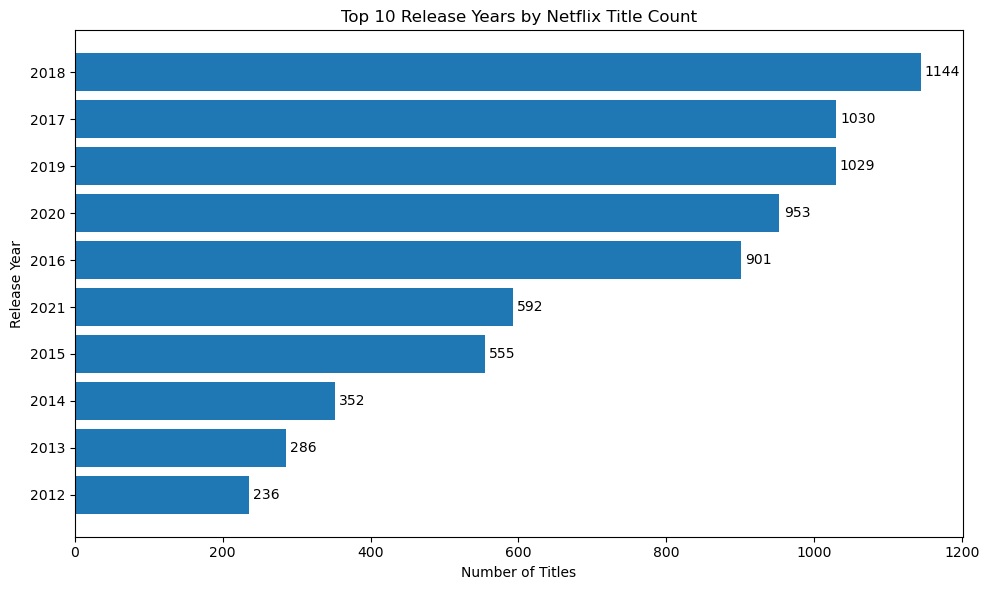

Charts saved successfully!
Output directory: /home/richard/Netflix_Fresh/outputs/figures


In [5]:

# Create output directory
output_dir = "/home/richard/Netflix_Fresh/outputs/figures"
os.makedirs(output_dir, exist_ok=True)

# Save the release-year trend line chart
plt.figure(figsize=(12, 6))
plt.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker="o",
    markersize=3,
    linewidth=1.5
)
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "release_year_trend.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save the top 10 release-years bar chart
plt.figure(figsize=(10, 6))
bars = plt.barh(
    top_10_years.index.astype(str),
    top_10_years.values
)
plt.title("Top 10 Release Years by Netflix Title Count")
plt.xlabel("Number of Titles")
plt.ylabel("Release Year")
plt.bar_label(bars, fmt="%d", padding=3)
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "top_10_release_years.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Charts saved successfully!")
print("Output directory:", output_dir)


## Business Insights: Netflix Release-Year Trend Analysis

This analysis examines the release years of 8,787 Netflix titles, covering the period from 1925 to 2021.

### Key Findings

- **2018 recorded the highest title count**, with 1,144 titles.
- 2017 ranked second with 1,030 titles, while 2019 ranked third with 1,029 titles.
- The dataset contains substantial representation of releases from 2015 to 2020.
- The count for 2021 was 592 titles, lower than the preceding years shown. This may reflect incomplete coverage of the year or differences in catalog availability.

### Business Recommendations

1. Examine audience engagement and viewing hours for titles from high-representation release years.
2. Compare older and newer titles to understand which age groups and content periods attract viewers.
3. Consider licensing and promoting older titles where audience demand supports doing so.
4. Use complete release and viewing data before making conclusions about production growth or decline.

### Conclusion

The dataset indicates that 2018 had the largest number of titles by release year. However, these counts describe the release years of titles in the available Netflix catalog, not Netflix's total annual production or actual audience popularity.

In [6]:

# Export yearly release statistics
output_dir = "/home/richard/Netflix_Fresh/outputs"
os.makedirs(output_dir, exist_ok=True)

yearly_results = yearly_counts.rename_axis(
    "release_year"
).reset_index(name="title_count")

yearly_results.to_csv(
    os.path.join(output_dir, "release_year_analysis.csv"),
    index=False
)

print("Release-year analysis exported successfully!")
print("Number of release years:", len(yearly_results))
print(
    "Saved to:",
    os.path.join(output_dir, "release_year_analysis.csv")
)


Release-year analysis exported successfully!
Number of release years: 74
Saved to: /home/richard/Netflix_Fresh/outputs/release_year_analysis.csv
